# TLS matrix with retained energy evidence
Twelve TLS 1.3 configurations, Ready Metrics 2 and ten planned reset-separated
attempts per configuration. This notebook reads the exported A1 dataset only.
Energy is captured by the campaign but joule analysis belongs to A6.
Do not equate synthetic test execution with experimental evidence.


In [1]:
# Configuration. The batch CLI supplies PQC_A2_* environment variables.
# For interactive reruns, choose a fresh OUTPUT directory.
import os, json, sys
from pathlib import Path
candidates = [Path("/workspace"), Path("/home/timk/rmit/PQC-Framework-02"), Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "scripts/framework/timing_dataset_loader.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("This kernel cannot access the repository; use ./scripts/dev.sh notebook")
sys.path.insert(0, str(ROOT / "scripts"))

#DATASET = Path(os.environ.get("PQC_A2_DATASET", str(ROOT / "results/analysis/tls_matrix_energy_dataset_01")))
#SPEC_FILE = Path(os.environ.get("PQC_A2_SPEC", str(ROOT / "notebooks/tls_matrix_energy.example.json")))
#OUTPUT = Path(os.environ.get("PQC_A2_OUTPUT", str(ROOT / "results/analysis/tls_matrix_energy_interactive_01")))
#SPEC = json.loads(SPEC_FILE.read_text())

DATASET = ROOT / "results/analysis/tls_matrix_energy_20260928_final_01"
SPEC_FILE = ROOT / "notebooks/tls_matrix_energy.example.json"
OUTPUT = ROOT / "results/analysis/tls_matrix_energy_20260928_notebook_02"
SPEC = json.loads(SPEC_FILE.read_text())

# Optional within-family view (uncomment both lines together):
# SPEC["filters"]["tls_kex"] = "ML_KEM_768"
# SPEC["baseline"] = "ML_KEM_768__rsa3072__server"
SPEC


{'conditions': {'secp256r1__rsa3072__server': {'tls_kex': 'secp256r1',
   'tls_auth': 'rsa3072',
   'auth_mode': 'server'},
  'secp256r1__rsa3072__mutual': {'tls_kex': 'secp256r1',
   'tls_auth': 'rsa3072',
   'auth_mode': 'mutual'},
  'secp256r1__mldsa65__server': {'tls_kex': 'secp256r1',
   'tls_auth': 'mldsa65',
   'auth_mode': 'server'},
  'secp256r1__mldsa65__mutual': {'tls_kex': 'secp256r1',
   'tls_auth': 'mldsa65',
   'auth_mode': 'mutual'},
  'SecP256r1MLKEM768__rsa3072__server': {'tls_kex': 'SecP256r1MLKEM768',
   'tls_auth': 'rsa3072',
   'auth_mode': 'server'},
  'SecP256r1MLKEM768__rsa3072__mutual': {'tls_kex': 'SecP256r1MLKEM768',
   'tls_auth': 'rsa3072',
   'auth_mode': 'mutual'},
  'SecP256r1MLKEM768__mldsa65__server': {'tls_kex': 'SecP256r1MLKEM768',
   'tls_auth': 'mldsa65',
   'auth_mode': 'server'},
  'SecP256r1MLKEM768__mldsa65__mutual': {'tls_kex': 'SecP256r1MLKEM768',
   'tls_auth': 'mldsa65',
   'auth_mode': 'mutual'},
  'ML_KEM_768__rsa3072__server': {'tls_kex

In [2]:
from framework.timing_summary import export_summary
from IPython.display import display, Image
frames = export_summary(DATASET, SPEC, OUTPUT)
display(frames["completeness"])


,condition,capture_class,evidence_class,metric,inventory_runs,excluded_runs,included_runs,completed_runs,failed_runs,unknown_runs,...,completion_ci_low,completion_ci_high,completion_ci_reason,capture_accepted_runs,valid_observations,unavailable_observations,contributing_runs,contributing_observations,contributing_iterations,runs_without_usable_metric
0,ML_KEM_768__mldsa65__mutual,tls_runtime,stm32_st67_pqc_tls_e2e,tls_handshake,10,0,10,10,0,0,...,None,None,independence_not_declared,10,10,0,10,10,10,0
1,ML_KEM_768__mldsa65__mutual,tls_runtime,stm32_st67_pqc_tls_e2e,mqtt_readiness,10,0,10,10,0,0,...,None,None,independence_not_declared,10,10,0,10,10,10,0
2,ML_KEM_768__mldsa65__mutual,tls_runtime,stm32_st67_pqc_tls_e2e,rtfb,10,0,10,10,0,0,...,None,None,independence_not_declared,10,10,0,10,10,10,0
3,ML_KEM_768__mldsa65__mutual,tls_runtime,stm32_st67_pqc_tls_e2e,rtlb,10,0,10,10,0,0,...,None,None,independence_not_declared,10,10,0,10,10,10,0
4,ML_KEM_768__mldsa65__mutual,tls_runtime,stm32_st67_pqc_tls_e2e,ttfb,10,0,10,10,0,0,...,None,None,independence_not_declared,10,10,0,10,10,10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,secp256r1__rsa3072__server,tls_runtime,stm32_st67_classical_tls_e2e,rtlb,10,0,10,10,0,0,...,None,None,independence_not_declared,10,10,0,10,10,10,0
92,secp256r1__rsa3072__server,tls_runtime,stm32_st67_classical_tls_e2e,ttfb,10,0,10,10,0,0,...,None,None,independence_not_declared,10,10,0,10,10,10,0
93,secp256r1__rsa3072__server,tls_runtime,stm32_st67_classical_tls_e2e,ttlb,10,0,10,10,0,0,...,None,None,independence_not_declared,10,10,0,10,10,10,0
94,secp256r1__rsa3072__server,tls_runtime,stm32_st67_classical_tls_e2e,req_tfb,10,0,10,10,0,0,...,None,None,independence_not_declared,10,10,0,10,10,10,0


The binary denominator is included completed + failed runs; unknown outcomes
and exclusions remain separate. Latencies are success-conditional and measurement
validity is separate from capture acceptance. Ten resets do not by themselves
establish independence; the preset leaves confidence intervals suppressed.
This preset uses exact evidence-class matching, so cross-classical/hybrid/pure-PQC
matched differences are refused. The library also supports explicit STM32 TLS/transport
policies; those still require justified treatment and matching controls. Missing controls also refuse matching. Inspect reasons instead of
waiving unknown controls. Multi-factor deltas are not isolated factor effects.


,condition,capture_class,evidence_class,metric,unit,n_runs,n_observations,q1,median,q3,iqr,p90,p95,median_ci_low,median_ci_high,median_ci_reason
0,ML_KEM_768__mldsa65__mutual,tls_runtime,stm32_st67_pqc_tls_e2e,tls_handshake,us,10,10,560851.0,583061.5,606116.0,45265.0,629083.6,642473.8,None,None,independence_not_declared
1,ML_KEM_768__mldsa65__mutual,tls_runtime,stm32_st67_pqc_tls_e2e,mqtt_readiness,us,10,10,779507.25,782741.0,832671.0,53163.75,860966.6,862643.3,None,None,independence_not_declared
2,ML_KEM_768__mldsa65__mutual,tls_runtime,stm32_st67_pqc_tls_e2e,rtfb,us,10,10,7735660.5,7806402.0,7826596.5,90936.0,7841205.6,7842094.8,None,None,independence_not_declared
3,ML_KEM_768__mldsa65__mutual,tls_runtime,stm32_st67_pqc_tls_e2e,rtlb,us,10,10,9617863.75,9685138.0,9710526.75,92663.0,9722132.0,9724355.0,None,None,independence_not_declared
4,ML_KEM_768__mldsa65__mutual,tls_runtime,stm32_st67_pqc_tls_e2e,ttfb,us,10,10,1171057.25,1220207.0,1231172.25,60115.0,1253740.6,1260236.8,None,None,independence_not_declared
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,secp256r1__rsa3072__server,tls_runtime,stm32_st67_classical_tls_e2e,rtlb,us,10,10,9521816.5,9568908.5,9585676.0,63859.5,9590599.5,9594129.75,None,None,independence_not_declared
92,secp256r1__rsa3072__server,tls_runtime,stm32_st67_classical_tls_e2e,ttfb,us,10,10,1135897.5,1136819.5,1139180.25,3282.75,1140553.9,1144549.45,None,None,independence_not_declared
93,secp256r1__rsa3072__server,tls_runtime,stm32_st67_classical_tls_e2e,ttlb,us,10,10,3006029.5,3008101.5,3012505.0,6475.5,3016209.7,3017432.35,None,None,independence_not_declared
94,secp256r1__rsa3072__server,tls_runtime,stm32_st67_classical_tls_e2e,req_tfb,us,10,10,126236.75,127031.0,128482.75,2246.0,130698.2,135280.1,None,None,independence_not_declared


,condition,baseline,metric,unit,delta_median,percent_difference,reason,percent_reason,baseline_runs,treatment_runs
0,secp256r1__rsa3072__mutual,secp256r1__rsa3072__server,tls_handshake,us,None,None,unknown_control:controls.mqtt.qos;unknown_cont...,unknown_control:controls.mqtt.qos;unknown_cont...,10,10
1,secp256r1__rsa3072__mutual,secp256r1__rsa3072__server,mqtt_readiness,us,None,None,unknown_control:controls.mqtt.qos;unknown_cont...,unknown_control:controls.mqtt.qos;unknown_cont...,10,10
2,secp256r1__rsa3072__mutual,secp256r1__rsa3072__server,rtfb,us,None,None,unknown_control:controls.mqtt.qos;unknown_cont...,unknown_control:controls.mqtt.qos;unknown_cont...,10,10
3,secp256r1__rsa3072__mutual,secp256r1__rsa3072__server,rtlb,us,None,None,unknown_control:controls.mqtt.qos;unknown_cont...,unknown_control:controls.mqtt.qos;unknown_cont...,10,10
4,secp256r1__rsa3072__mutual,secp256r1__rsa3072__server,ttfb,us,None,None,unknown_control:controls.mqtt.qos;unknown_cont...,unknown_control:controls.mqtt.qos;unknown_cont...,10,10
...,...,...,...,...,...,...,...,...,...,...
83,ML_KEM_768__mldsa65__mutual,secp256r1__rsa3072__server,rtlb,us,None,None,unknown_control:controls.mqtt.qos;conflicting_...,unknown_control:controls.mqtt.qos;conflicting_...,10,10
84,ML_KEM_768__mldsa65__mutual,secp256r1__rsa3072__server,ttfb,us,None,None,unknown_control:controls.mqtt.qos;conflicting_...,unknown_control:controls.mqtt.qos;conflicting_...,10,10
85,ML_KEM_768__mldsa65__mutual,secp256r1__rsa3072__server,ttlb,us,None,None,unknown_control:controls.mqtt.qos;conflicting_...,unknown_control:controls.mqtt.qos;conflicting_...,10,10
86,ML_KEM_768__mldsa65__mutual,secp256r1__rsa3072__server,req_tfb,us,None,None,unknown_control:controls.mqtt.qos;conflicting_...,unknown_control:controls.mqtt.qos;conflicting_...,10,10


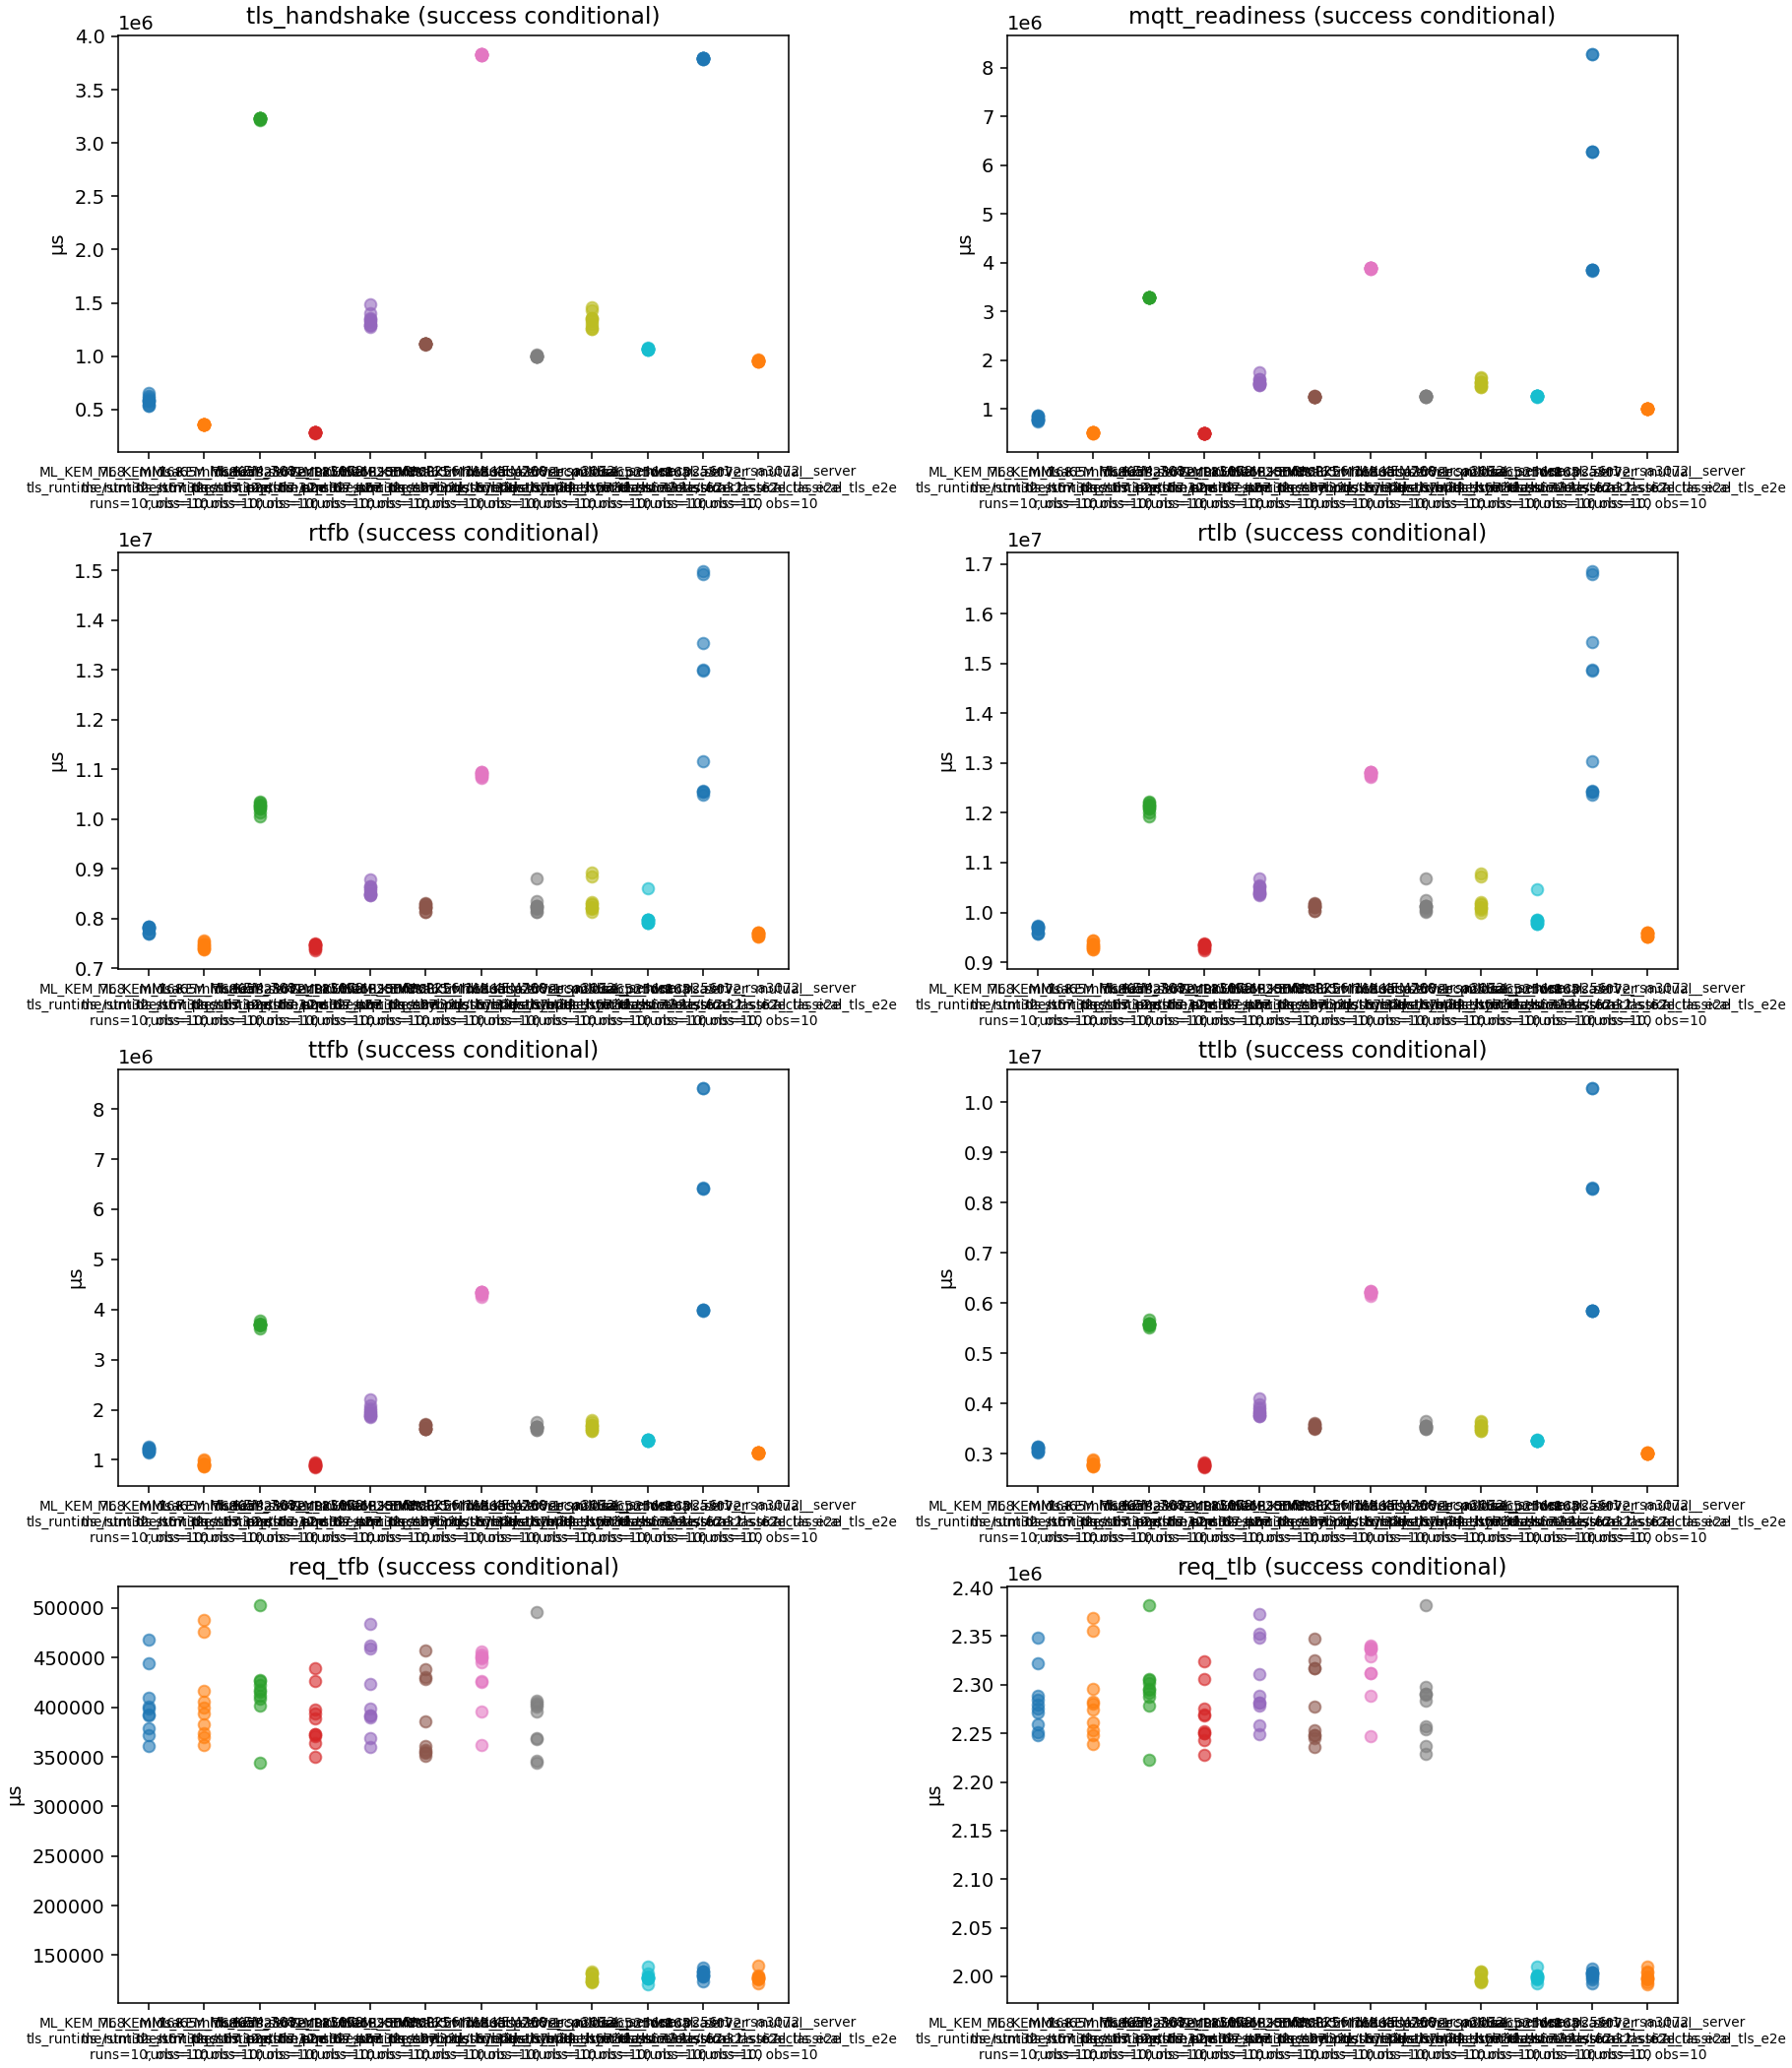

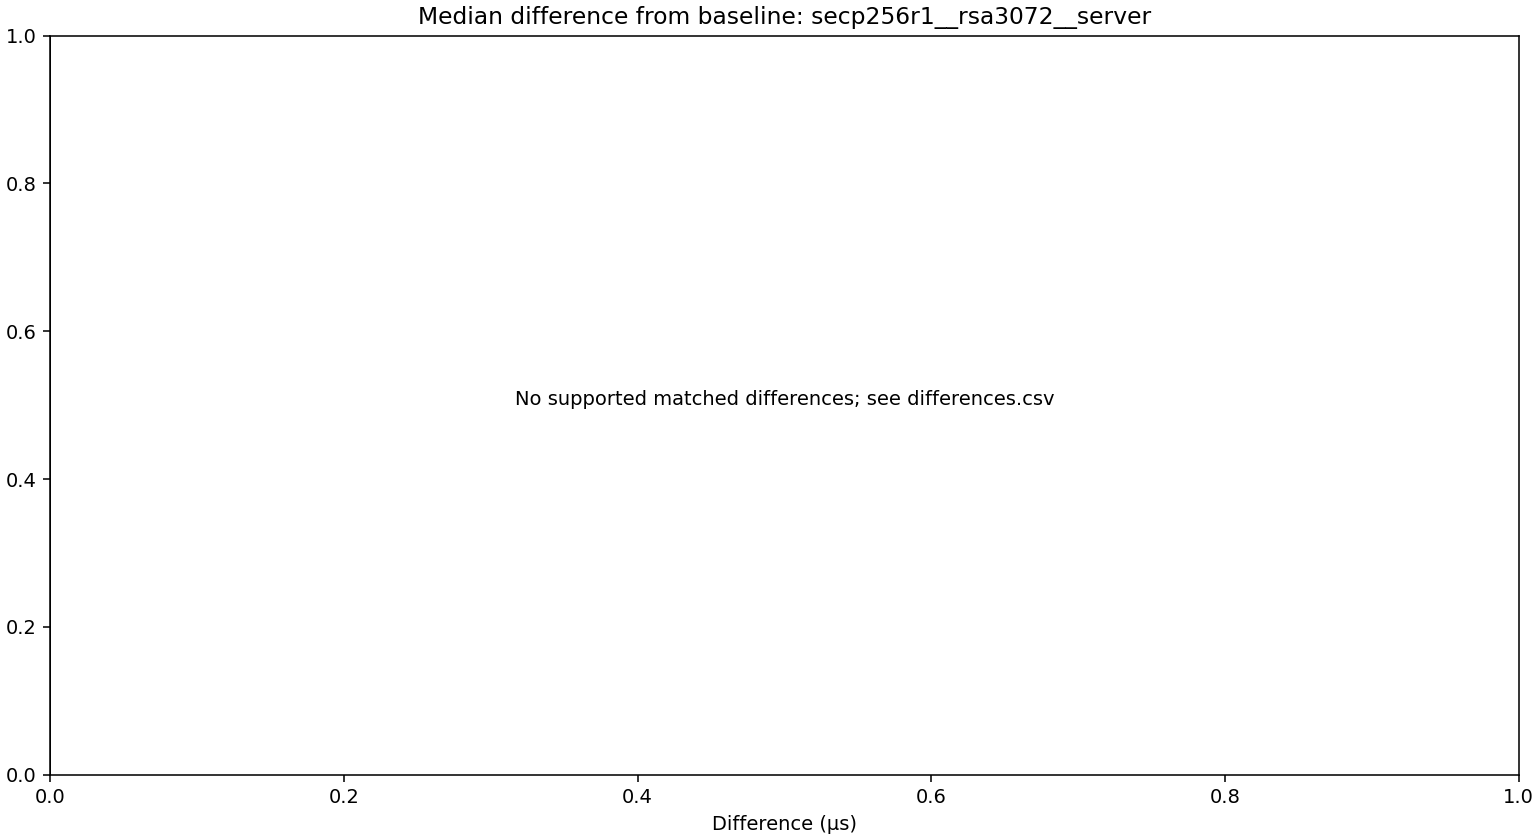

In [3]:
# Available timing summaries, including TLS and the RM2 payload boundaries.
display(frames["distributions"])
display(frames["differences"])
display(Image(filename=str(OUTPUT / "timing-distributions.png")))
display(Image(filename=str(OUTPUT / "matched-differences.png")))
